Heart Disease Prediction Classification:

1. Business Problem :
    a patient has heart disease or not (binary classification 1 or 0)
    accuracy should be high

2. Eplore data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import sklearn

heart_disease = pd.read_csv("../matplotlib/heart-disease.csv")
heart_disease


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [2]:
heart_disease.shape


(303, 14)

In [3]:
heart_disease.dtypes #sex : integer (1, 0)  
#all values are numerical, no str values, no hotencoding

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

In [ ]:
heart_disease.isna().sum()  # no missing values

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [8]:
#study balance data, how many 1s and 0s
heart_disease['target'].value_counts() 

target
1    165
0    138
Name: count, dtype: int64

3. Data Preparation & Pipline

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


In [5]:
X =heart_disease.drop('target', axis=1)
y = heart_disease['target']
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((227, 13), (76, 13), (227,), (76,))

4. Train the model (logistic regression model)

In [12]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model",  LogisticRegression(max_iter= 1000)) #max iteration, so it coverges, stop
    
])

model.fit(X_train, y_train)
model.score(X_test, y_test )  # for a classifier, .score() = accuracy




c:\Users\user\Desktop\AIBuilders_Data_Analysis\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8947368421052632

In [14]:
#predict vs predict_proba

# Hard decisions, show first five
model.predict(X_test[:5])
#result first 3 have disease, 2 don't have 

array([0, 1, 1, 0, 1])

In [25]:
# Confidence behind those decisions - two columns: P(class 0), P(class 1)
model.predict_proba(X_test[:5]) #probability of each prediction 

array([[0.00679478, 0.99320522],
       [0.05173386, 0.94826614],
       [0.11883682, 0.88116318],
       [0.96908307, 0.03091693],
       [0.81842958, 0.18157042]])

5. Evaluation 

In [ ]:
#in medical, we don't use only score, accuracy 

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_preds = model.predict(X_test)
confusion_matrix(y_test,y_preds)

array([[26,  5],
       [ 4, 41]])

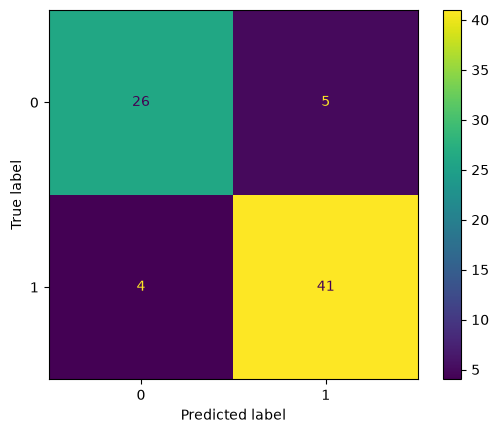

In [29]:
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_preds);

In [30]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_preds)

0.881578947368421

In [31]:
#report classification
from sklearn.metrics import classification_report
# precision, recall, f1-score, support - for each class
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.87      0.84      0.85        31
           1       0.89      0.91      0.90        45

    accuracy                           0.88        76
   macro avg       0.88      0.87      0.88        76
weighted avg       0.88      0.88      0.88        76



AUC: 0.919


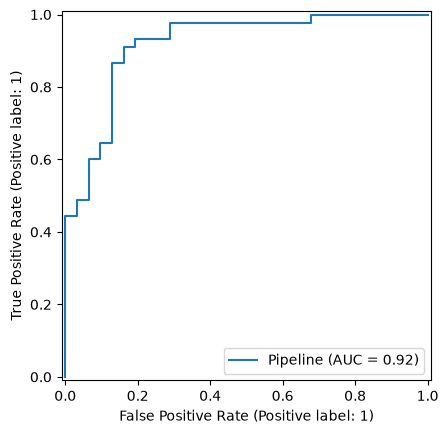

In [32]:
#ROC curve
from sklearn.metrics import RocCurveDisplay, roc_auc_score

# Probabilities of the positive class
y_probs = model.predict_proba(X_test)[:, 1]

print(f"AUC: {roc_auc_score(y_test, y_probs):.3f}")

RocCurveDisplay.from_estimator(estimator=model, X=X_test, y=y_test);

6. Improve the model 

In [41]:
#we try another model RandomForestClassifier


from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps = [
        ("imputer", SimpleImputer(strategy = "median")),
        ("model", RandomForestClassifier())
    
])

rf_model.fit(X_train, y_train)
#evaluate
print(f"Forest accuracy : {rf_model.score(X_test, y_test) :.3f}")

#previuos model
print(f"LogReg accuracy : {model.score(X_test, y_test):.3f}")



Forest accuracy : 0.855
LogReg accuracy : 0.882


#tunning of forest classifier

In [42]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 200, 500],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 4, 6],
}

# scoring="recall" - tune toward catching sick patients, not raw accuracy
gs = GridSearchCV(rf_model, param_grid, cv=5, scoring="recall", verbose=2)
gs.fit(X_train, y_train)
print(gs.best_params_)
print(f"Best CV recall: {gs.best_score_:.3f}")

Fitting 5 folds for each of 27 candidates, totalling 135 fits
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=100; total time=   0.3s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=100; total time=   0.4s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=100; total time=   0.4s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=100; total time=   0.3s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=100; total time=   0.3s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=200; total time=   0.6s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=200; total time=   1.1s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=200; total time=   1.3s
[CV] END model__max_depth=None, model__min_samples_split=2, model__n_estimators=200; total time=   0.9s
[C

In [43]:
import pickle
from joblib import dump, load

best_model = gs.best_estimator_

# pickle
pickle.dump(best_model, open("heart_disease_model.pkl", "wb"))
loaded = pickle.load(open("heart_disease_model.pkl", "rb"))
print(f"Loaded (pickle) accuracy: {loaded.score(X_test, y_test):.3f}")

# joblib
dump(best_model, "heart_disease_model.joblib")
loaded_joblib = load("heart_disease_model.joblib")
print(f"Loaded (joblib) accuracy: {loaded_joblib.score(X_test, y_test):.3f}")

Loaded (pickle) accuracy: 0.842
Loaded (joblib) accuracy: 0.842
